<a href="https://colab.research.google.com/github/Aditesh26/Probabilistic-SMS-Spam-Detection/blob/main/ProbStat_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

!wget -q https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip -O sms.zip
!unzip -o -q sms.zip

df = pd.read_csv("SMSSpamCollection", sep="\t", header=None,
                 names=["label", "message"])

print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())

before = len(df)
df = df.drop_duplicates(subset="message").reset_index(drop=True)
print("Duplicates removed:", before - len(df))

df["label"] = df["label"].str.strip().str.lower().map({"spam": 1, "ham": 0})

print("Cleaned shape:", df.shape)
print(df.head())

Shape: (5572, 2)
Missing values:
 label      0
message    0
dtype: int64
Duplicates removed: 403
Cleaned shape: (5169, 2)
   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...


Total messages: 5169
Spam: 653 | Ham: 4516
P(Spam) = 0.1263
P(Ham)  = 0.8737


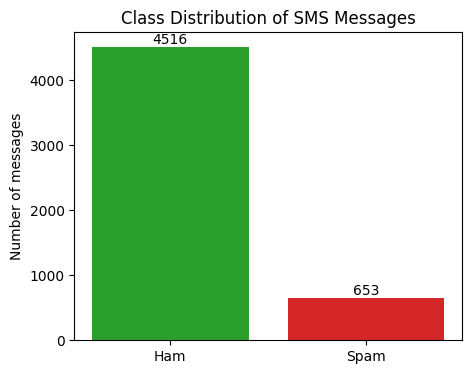

In [ ]:
# Class counts
n_total = len(df)
n_spam = (df["label"] == 1).sum()
n_ham = (df["label"] == 0).sum()

p_spam = n_spam / n_total
p_ham = n_ham / n_total

print("Total messages:", n_total)
print("Spam:", n_spam, "| Ham:", n_ham)
print(f"P(Spam) = {p_spam:.4f}")
print(f"P(Ham)  = {p_ham:.4f}")

# Bar chart
plt.figure(figsize=(5, 4))
plt.bar(["Ham", "Spam"], [n_ham, n_spam], color=["tab:green", "tab:red"])
plt.title("Class Distribution of SMS Messages")
plt.ylabel("Number of messages")
for i, v in enumerate([n_ham, n_spam]):
    plt.text(i, v, str(v), ha="center", va="bottom")
plt.show()

In [ ]:
words = ["free", "prize", "win", "urgent", "offer"]

# Lowercase text for matching
df["text_lower"] = df["message"].str.lower()

results = []
for w in words:
    # whole-word match using regex
    pattern = r"\b" + re.escape(w) + r"\b"
    has_word = df["text_lower"].str.contains(pattern, regex=True)

    n_word = has_word.sum()
    n_word_spam = (has_word & (df["label"] == 1)).sum()

    p_direct = n_word_spam / n_word

    p_w_given_spam = n_word_spam / n_spam
    p_w = n_word / n_total
    p_bayes = (p_w_given_spam * p_spam) / p_w

    results.append([w, n_word, n_word_spam, round(p_w_given_spam, 4),
                    round(p_w, 4), round(p_direct, 4), round(p_bayes, 4)])

table = pd.DataFrame(results, columns=[
    "word", "msgs_with_word", "spam_with_word",
    "P(W|Spam)", "P(W)", "P(Spam|W) direct", "P(Spam|W) Bayes"])
print(table.to_string(index=False))

  word  msgs_with_word  spam_with_word  P(W|Spam)   P(W)  P(Spam|W) direct  P(Spam|W) Bayes
  free             203             148     0.2266 0.0393            0.7291           0.7291
 prize              73              73     0.1118 0.0141            1.0000           1.0000
   win              55              49     0.0750 0.0106            0.8909           0.8909
urgent              62              57     0.0873 0.0120            0.9194           0.9194
 offer              30              24     0.0368 0.0058            0.8000           0.8000


In [ ]:
p = p_spam

E_Y = p
Var_Y = p * (1 - p)

print(f"E(Y)   = {E_Y:.4f}  | numpy mean: {np.mean(df['label']):.4f}")
print(f"Var(Y) = {Var_Y:.4f}  | numpy var:  {np.var(df['label']):.4f}")

E(Y)   = 0.1263  | numpy mean: 0.1263
Var(Y) = 0.1104  | numpy var:  0.1104


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

X = df["message"]
y = df["label"]

# 80/20 split, stratified to keep spam-ham ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train size:", len(X_train), "| Test size:", len(X_test))
print("Spam ratio train:", round(y_train.mean(), 4))
print("Spam ratio test: ", round(y_test.mean(), 4))

# Convert text to word-count features
vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)   # fit only on train
X_test_vec = vectorizer.transform(X_test)

print("Feature matrix shape (train):", X_train_vec.shape)

Train size: 4135 | Test size: 1034
Spam ratio train: 0.1262
Spam ratio test:  0.1267
Feature matrix shape (train): (4135, 7680)


Accuracy: 0.9816
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       903
        Spam       0.96      0.89      0.92       131

    accuracy                           0.98      1034
   macro avg       0.97      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034

Confusion matrix:
 [[898   5]
 [ 14 117]]
Spam classified as genuine (FN): 14
Genuine classified as spam (FP): 5


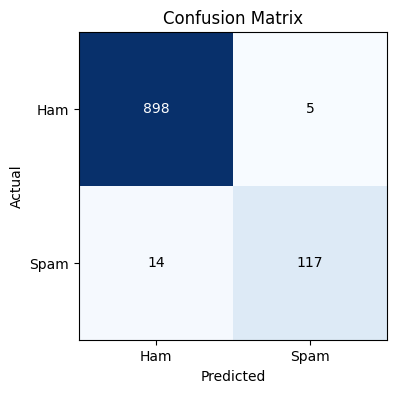

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Train
model = MultinomialNB()
model.fit(X_train_vec, y_train)

# Predict
y_pred = model.predict(X_test_vec)

# Metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=["Ham", "Spam"]))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix:\n", cm)
print("Spam classified as genuine (FN):", fn)
print("Genuine classified as spam (FP):", fp)

# Plot
plt.figure(figsize=(4, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks([0, 1], ["Ham", "Spam"])
plt.yticks([0, 1], ["Ham", "Spam"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.show()

In [ ]:
def predict_sms(text):
    vec = vectorizer.transform([text])
    probs = model.predict_proba(vec)[0]
    label = "Spam" if probs[1] > probs[0] else "Ham"
    print(f"Prediction: {label}")
    print(f"P(Spam | Message) = {probs[1]:.2f}")
    print(f"P(Ham | Message)  = {probs[0]:.2f}")

# Test with user input
msg = input("Enter an SMS message: ")
predict_sms(msg)

Enter an SMS message: Hey, are we meeting for lunch today?
Prediction: Ham
P(Spam | Message) = 0.00
P(Ham | Message)  = 1.00
